# Morocco 

This script is using a sample from the ERA5--Drought data set from the European Centre for Medium-range Weather Forecasts (ECMWF) and plots a timeseries for Morocco

## Setup and Settings

#### Load libraries

In [1]:
import os 
import sys
import math
import datetime as dt
import pandas as pd
import netCDF4 as nc4
import numpy as np
import xarray as xr
import cartopy.crs as ccrs
import geopandas as gpd
import fiona
import regionmask
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import AutoMinorLocator
import string
from dateutil import relativedelta
import cartopy
import cartopy.feature as feature
import cartopy.io.shapereader as shapereader

#### Some helpful functions

In [2]:
EARTHRADIUS = 6371  # earth radius [km]
def calculate_gridarea(lats_centr, res, nlon):

    lats1 = (lats_centr + (res / 2)) * np.pi / 180  # np.sin requires radians
    lats2 = (lats_centr - (res / 2)) * np.pi / 180
    areas = (
        (np.pi / 180) * (EARTHRADIUS ** 2) * np.abs(np.sin(lats1) - np.sin(lats2)) * res
    )

    ## overwrite any areas of 0 (at the poles) with np.NaN to prevent problems
    areas[np.where(areas == 0.0)] = np.nan
    # return array of dimension nlat x nlon
    area_2d = np.swapaxes(np.tile(areas, (nlon, 1)), 0, 1)
    return area_2d

#### General settings

In [3]:
ref_syyyy = 1991
ref_eyyyy = 2020
yyyy_start= 1940
yyyy_end  = 2026
indicator = "SPEI"
window    = 12
yyyy      = 2025
mm        = "03"
dataset   = "era5"
stream    = "moda"
distribut = "genlogistic"
# new versions
ipath     = f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#%{yyyy}{mm}01/hr"
#ipath_era5t= f"/ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/"#{yyyy}{mm}01/hr"
lpath     = "/ec/vol/centaur/nejk/drought_monitor"
country   = "Morocco"

In [4]:
dates = pd.date_range(start=f"{yyyy_start}-01-01",end=f"{yyyy_end}-01-01", freq='ME')
pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]#[window:]
#pdate_seq = [dt.datetime.strptime(str(i)[0:10], "%Y-%m-%d") for i in dates]
#if (yyyy_start - 1940 -window) < 0: 
print(dates)
print(dates.size)
#print(pdate_seq)
#print(pdate_seq.size)

DatetimeIndex(['1940-01-31', '1940-02-29', '1940-03-31', '1940-04-30',
               '1940-05-31', '1940-06-30', '1940-07-31', '1940-08-31',
               '1940-09-30', '1940-10-31',
               ...
               '2025-03-31', '2025-04-30', '2025-05-31', '2025-06-30',
               '2025-07-31', '2025-08-31', '2025-09-30', '2025-10-31',
               '2025-11-30', '2025-12-31'],
              dtype='datetime64[ns]', length=1032, freq='ME')
1032


### Landmask and area

In [5]:
# binary land mask
lfile      = f"{lpath}/landmask_era5_global.nc"
lmask      = xr.open_dataset(lfile)['lsm']
lmask      = lmask.where( lmask.values == 1 ) # set 0s to nan
# land fraction
lffile     = f"{lpath}/landmask_era5_global_frac.nc"
lmask_frac = xr.open_dataset(lffile)['var172']

/usr/local/apps/python3/3.12.9-01/lib/python3.12/site-packages/gribapi/__init__.py:23: UserWarning: ecCodes 2.39.0 or higher is recommended. You are running version 2.31.0
  warnings.warn(


### Country / Region of interest

  shapeName shapeISO               shapeID shapeGroup shapeType  \
0   Morocco      MAR  5654995B609903263945        MAR      ADM0   

                                            geometry  
0  POLYGON ((-5.40129 35.92231, -5.40144 35.92197...  
(721, 1440)


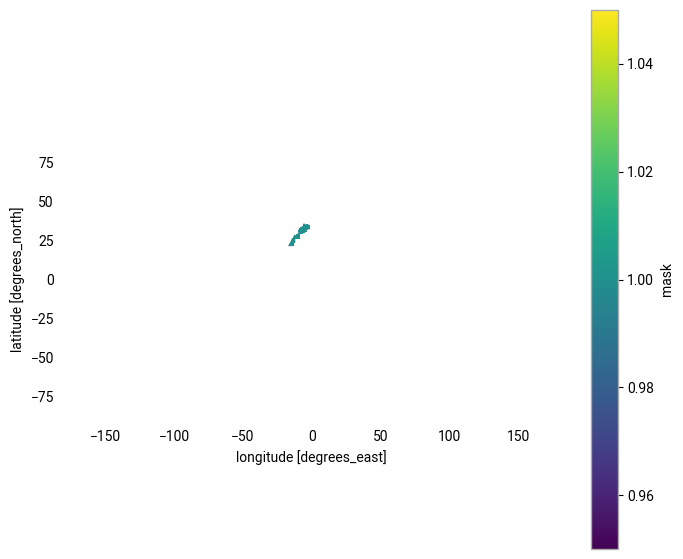

In [6]:
#regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].plot()
#mask = regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].mask(lmask.lon, lmask.lat)
#mask = xr.where(np.isnan(mask), np.nan, 1)
#mask.plot()


# use external shapefile to incl contended territories?
shpfile = gpd.read_file("./regions/geoBoundaries-MAR-ADM0-all/geoBoundaries-MAR-ADM0.shp")
print(shpfile.head())

shpfile.plot()
shpfile=shpfile.to_crs('epsg:4326')

# get mask of grid points in countryshp
mask = regionmask.mask_geopandas(shpfile, lmask.lon, lmask.lat)
print(mask.shape)
mask = xr.where(mask == 0, 1, np.nan)
mask.plot()
#mask = xr.DataArray(maski, coords={'lat': lmask.lat, 'lon': lmask.lat}, dims=["lat", "lon"])
#mask = mask.where( mask.values == 0, np.nan) # to get nan in all other cases, 0 otherwise
#mask = mask.where( np.isnan(mask.values), 1) # to set the 0 from regionmask to 1
#print(mask)
#mask.plot()


In [47]:
lon1 = math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][0])
lon2 = math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][2])
lat1 = math.floor(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][1])
lat2 = math.ceil(regionmask.defined_regions.natural_earth_v5_0_0.countries_110[[country]].bounds[0][3])
print(f"Bounding box: lats {lat1} to {lat2}, lons {lon1} to {lon2}")

Bounding box: lats 21 to 36, lons -18 to -1


## ERA5-based drought

### Read drought index 

In [48]:
filedate_seq = [dt.datetime.strftime(i, "%Y%m01") for i in pdate_seq[window:]]
filelist = []
for idate in filedate_seq[:-8]:
    # /ec/ws4/tc/emos/work/cems/dryfall/emos/dryfall_monthly/ens/runs/
    ifile = f"{ipath}/era5/{idate}/hr/{indicator}{window}_{distribut}_global_era5_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
    if os.path.exists(ifile):
        filelist.append(ifile)
    else:
        ifile = f"{ipath}/era5t/{idate}/hr/{indicator}{window}_{distribut}_global_era5t_{stream}_ref{ref_syyyy}to{ref_eyyyy}_{str(idate)[:6]}.nc"
        filelist.append(ifile)
#print(filelist[:-8])

drought_index = {}
drought_index[window] = xr.open_mfdataset(filelist).sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
print(drought_index[window])

<xarray.Dataset> Size: 34MB
Dimensions:  (time: 1012, lat: 61, lon: 69)
Coordinates:
  * time     (time) datetime64[ns] 8kB 1941-01-01T06:00:00 ... 2025-04-01T06:...
  * lat      (lat) float64 488B 36.0 35.75 35.5 35.25 ... 21.75 21.5 21.25 21.0
  * lon      (lon) float64 552B -18.0 -17.75 -17.5 -17.25 ... -1.5 -1.25 -1.0
Data variables:
    SPEI12   (time, lat, lon) float64 34MB dask.array<chunksize=(1, 61, 69), meta=np.ndarray>
Attributes: (12/17)
    title:                   SPEI12
    description:             Drought Index: Standardized Drought Index calcul...
    Conventions:             CF-1.8
    history:                 Created 13/08/2024 15:02:13 using DRYFALL.
    institution:             European Centre for Medium-Range Weather Forecasts
    source:                  DRYFALL v1.0
    ...                      ...
    resolution:              0.25x0.25
    climate_start_date:      1991-01-01
    climate_end_date:        2020-12-31
    frequency:               Monthly
    contac

### Mask drought index

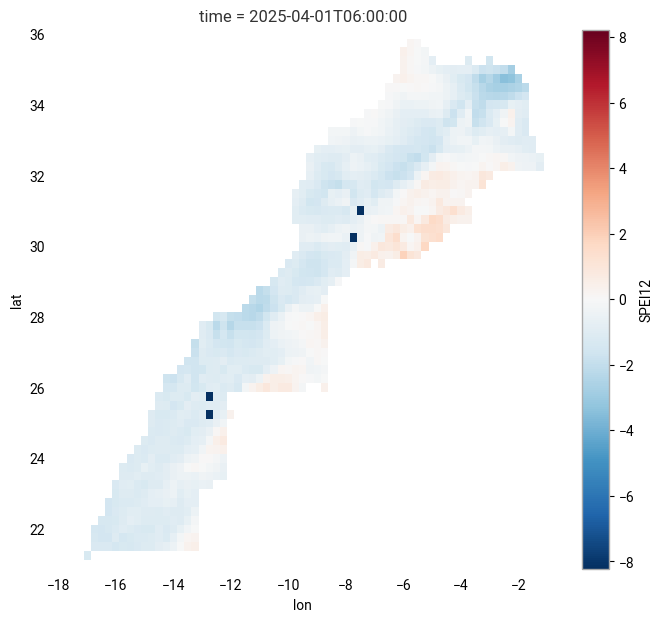

In [9]:
masked_drought_index = drought_index[window] * mask
masked_drought_index = xr.where(masked_drought_index == -9999, np.nan, masked_drought_index)
masked_drought_index.isel(time=-1)[f'{indicator}{window}'].plot()

area_2d = calculate_gridarea(masked_drought_index.lat, res=abs(masked_drought_index.lat[1]-masked_drought_index.lat[0]), nlon=len(masked_drought_index.lon))*lmask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))[0,:,:]
area_2d = xr.DataArray(area_2d, coords={'lat': masked_drought_index.lat,'lon': masked_drought_index.lon}, dims=["lat", "lon"])
area_2d_adj = area_2d * lmask_frac.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
area_2d_adj = area_2d_adj.where( area_2d_adj.values != 0 ) # set 0s to nan
mask_cut = mask.sel(lon=slice(lon1, lon2), lat=slice(lat2, lat1))
#area_2d.plot()
#area_2d_adj.plot()

### Calculate area in drought

In [10]:
#robinson = ccrs.Robinson().proj4_init

In [11]:
# calculate area in drought
area_3d_adj = area_2d_adj.reindex_like(masked_drought_index, method="nearest")
aid = {}

swindow=f"w{window}"
aid[swindow] = {}

for severity in ['moderate','severe','extreme','any']:
        
    if severity == "mild":
        thresh_min = -1
        thresh_max = 0
    if severity == "moderate":
        thresh_min = -1.5
        thresh_max = -1
    if severity == "severe":
        thresh_min = -2
        thresh_max = -1.5
    if severity == "extreme":
        thresh_min = -999
        thresh_max = -2
    if severity == "any":
        thresh_min = -999
        thresh_max = -1

    rdi = masked_drought_index[f'{indicator}{window}']
    dmask  = xr.where((rdi > thresh_min) & (rdi <= thresh_max) & (rdi != -9999), 1, np.nan)
    tmp    = 100 * (dmask*area_3d_adj).sum(dim=["lat", "lon"]) / (mask_cut*area_3d_adj).sum(dim=["lat", "lon"])
    aid[swindow][severity] = tmp.to_pandas() 

    del(tmp, dmask)

### Plot timeseries of area in drought

In [49]:
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']

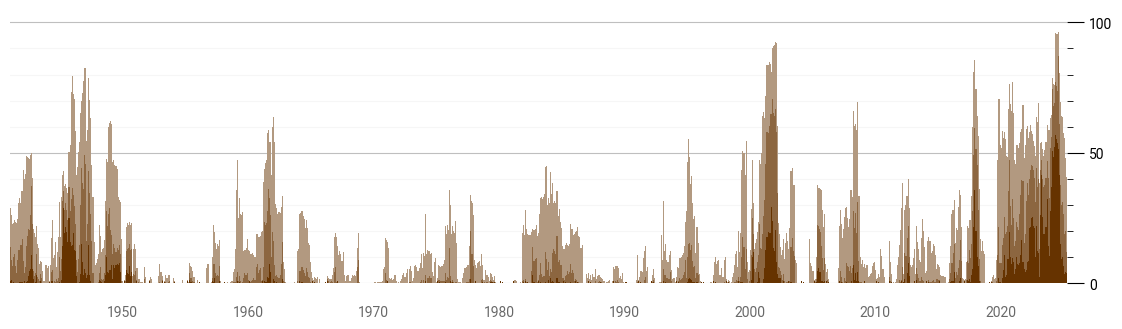

In [13]:
fig, ax1 = plt.subplots(1,1, figsize=(12,4))
#title1 = r"$\bf{" + f"{string.ascii_lowercase[0]}" + "}$"
#fig.suptitle(f"{title1} | Percent of {country} in drought ({indicator}-{window})", fontsize=22)
#fig.suptitle(f"Area of {country} in long-term drought ({indicator}-{window})", fontsize=22)
fig.tight_layout(pad=3.75)
fig.subplots_adjust(top=0.875)
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 20}
plt.rc('font', **font)

severities = ['extreme','severe','moderate']
pidata2 = aid[f'w{window}']['extreme']#[f'{indicator}{window}']
pidata3 = aid[f'w{window}']['severe']#[f'{indicator}{window}']
pidata4 = aid[f'w{window}']['moderate']#[f'{indicator}{window}']
apidata = pd.concat([pidata2, pidata3, pidata4], axis=1)
#apidata.index = apidata.index.shift(-(window-1), freq="MS") # shift datetimeindex to get start date
bottom = np.zeros(len(apidata.index))
for i in range(len(apidata.columns)):
    p = ax1.bar(apidata.index, apidata.iloc[:,i], facecolor=mycollisthex[i+1], 
                alpha=1, 
                width=relativedelta.relativedelta(months=1), 
                label=severities[i], 
                bottom=bottom,
                align='edge')
    bottom += apidata.iloc[:,i]
#ax1.set_ylabel("Area in drought [%]", size=18)
#ax1.legend(ncol=3, loc='upper center', fancybox=False, shadow=False, reverse=True, fontsize=12)
ax1.margins(x=0)
ax1.spines['top'].set_visible(False)
ax1.spines['right'].set_visible(False)
ax1.spines['left'].set_visible(False)
#ax1.tick_params(axis='y', colors='dimgray')
ax1.tick_params(axis='x', colors='dimgray')
ax1.xaxis.label.set_color('None')
ax1.yaxis.label.set_color('None')
ax1.minorticks_on()
ax1.xaxis.set_minor_locator(AutoMinorLocator(10))
# Major ticks every 20, minor ticks every 5
#https://stackoverflow.com/questions/24943991/change-grid-interval-and-specify-tick-labels
major_ticks = np.arange(0, 150, 50)
minor_ticks = np.arange(0, 150, 10)
ax1.set_yticks(major_ticks)
#ax1.set_yticks(minor_ticks, minor=True)
ax1.yaxis.tick_right()
# And a corresponding grid
#ax1.grid(which='minor')
# Or if you want different settings for the grids:
#ax.grid(which='minor', alpha=0.2)
#ax.grid(which='major', alpha=0.5)
ax1.tick_params(which='minor', length=4)
ax1.tick_params(which='major', length=12)
#ax1.grid(True)
ax1.set_axisbelow(True)
ax1.yaxis.grid(which='major', alpha=0.5, color='gray', linestyle='solid', zorder=3) #dashed
ax1.yaxis.grid(which='minor', alpha=0.2, color='lightgray', linestyle='solid', zorder=3) #dashed
ax1.set_ylim([0,105])
#for tick in ax1.get_xticklabels():
#    tick.set_rotation(45)
    
plt.savefig(f"figures/{country}_{indicator}{window}_AID_timeseries_monthly.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            facecolor='auto', edgecolor='auto',
            backend=None)
plt.show()

### Plot maps for specific events

<class 'geopandas.geodataframe.GeoDataFrame'>
time
2024-08-01 06:00:00    96.206405
2024-05-01 06:00:00    95.792518
2024-06-01 06:00:00    95.589082
2024-07-01 06:00:00    95.400014
2002-01-01 06:00:00    92.396503
2002-02-01 06:00:00    92.107559
2001-12-01 06:00:00    91.192847
2001-11-01 06:00:00    90.969891
2001-10-01 06:00:00    90.142615
2017-12-01 06:00:00    85.444543
dtype: float64
[np.int64(1003), np.int64(1000), np.int64(1001), np.int64(1002), np.int64(732), np.int64(733), np.int64(731), np.int64(730), np.int64(729), np.int64(923)]
[np.int64(1003), np.int64(1000), np.int64(1001), np.int64(1002), np.int64(732), np.int64(733), np.int64(731), np.int64(730), np.int64(729), np.int64(923), np.int64(849), np.int64(722)]
2024-05
figures/NEW_Morocco_map_SPEI12_202405.png


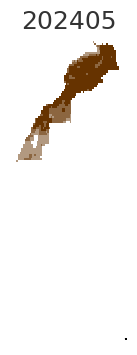

2024-06
figures/NEW_Morocco_map_SPEI12_202406.png


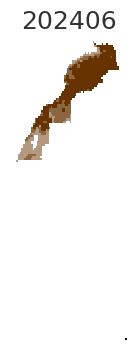

2024-07
figures/NEW_Morocco_map_SPEI12_202407.png


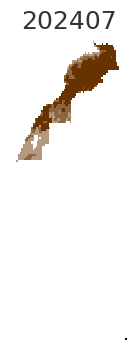

2024-08
figures/NEW_Morocco_map_SPEI12_202408.png


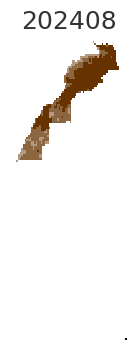

2024-09
figures/NEW_Morocco_map_SPEI12_202409.png


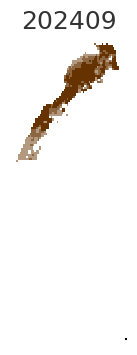

2024-10
figures/NEW_Morocco_map_SPEI12_202410.png


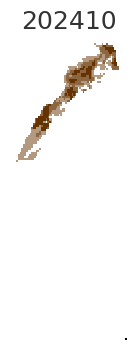

2024-11
figures/NEW_Morocco_map_SPEI12_202411.png


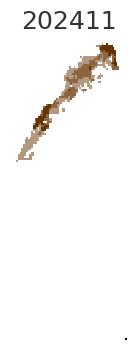

2024-12
figures/NEW_Morocco_map_SPEI12_202412.png


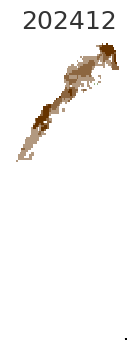

2025-01
figures/NEW_Morocco_map_SPEI12_202501.png


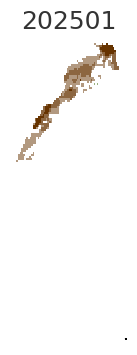

2025-02
figures/NEW_Morocco_map_SPEI12_202502.png


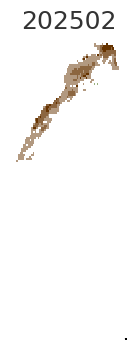

2025-03
figures/NEW_Morocco_map_SPEI12_202503.png


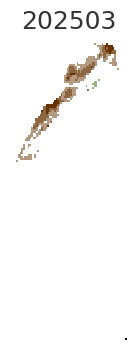

2025-04
figures/NEW_Morocco_map_SPEI12_202504.png


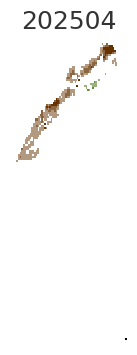

1941-01
figures/NEW_Morocco_map_SPEI12_194101.png


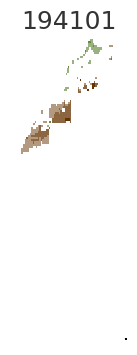

In [14]:
country = "Morocco"
#countries = shapereader.natural_earth(resolution='110m',
#                              category='cultural',
#                              name='admin_0_countries')

#highlight_countries = [country]
#for icountry in shapereader.Reader(countries).records():
#    if icountry.attributes['ADMIN'] in highlight_countries:
#        country_geom = icountry.geometry
        
mylevels     = [-10000,-1000,-2,-1.5,-1,1,1.5,2,1000]
mycollisthex = ['#bebebe','#663300','#8c6640','#b29980','#ffffff','#99b280','#668c40','#336600']
legnames     = ["masked","extremely dry", "severely dry", "moderately dry", "near normal", "moderately wet", "severely wet", "extremely wet"]

font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 16}
plt.rc('font', **font)

print(type(shpfile[['geometry']]))
n = 10
nmax_indices = []
print(apidata.sum(axis=1).sort_values(ascending=False)[0:10,])
for i in range(n):
    nmax_indices.append(np.flatnonzero(apidata.index == apidata.sum(axis=1).sort_values(ascending=False).index[i])[0])
print(nmax_indices)
# manually add 1992-11
nmax_indices.append(np.where(apidata.index.strftime("%Y-%m") == "2011-10")[0][0])
nmax_indices.append(np.where(apidata.index.strftime("%Y-%m") == "2001-03")[0][0])
print(nmax_indices)

#i = 0
#for itime in nmax_indices:
for itime in range(-12,1):
    toplot       = masked_drought_index.isel(time=itime)[f'{indicator}{window}']#['SPEI12'] * nutsmask_3d_xr.isel(time=itime)
    print(str(toplot.time.values)[:7])
    
    plt.figure(figsize=(4.5, 4));
    ax = plt.axes(projection=ccrs.Robinson(), frameon=False);
    #ax.coastlines(color='black', lw=0.25)
    toplot.plot(ax=ax, transform=ccrs.PlateCarree(),
                              x='lon', y='lat',
                              add_colorbar=False,
                              colors=mycollisthex,
                              levels=mylevels)
    #ax.set_xlim([lon1,lon2])
    #ax.set_ylim([lat1,lat2])
    
    #title1 = r"$\bf{" + f"{string.ascii_lowercase[i]}" + "}$"
    #ax.set_title(f"{title1} | {str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    ax.set_title(f"{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}", size=18)
    
    #ax.add_feature(shpfile, color='black', lw=0.3)
    #ax.add_geometries([], crs=ccrs.PlateCarree(), edgecolor='black', facecolor="None", linewidth=0.75)
    shpfile.plot(ax=ax, edgecolor='black', facecolor="None", linewidth=0.75)
    #plt.savefig(f"figures/{country}_{string.ascii_lowercase[i]}_map_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.pdf", dpi=300, format=None, metadata=None,
    print(f"figures/NEW_{country}_map_{indicator}{window}_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.png")
    plt.savefig(f"figures/NEW_{country}_map_{indicator}{window}_{str(toplot.time.values)[:4]}{str(toplot.time.values)[5:7]}.png", dpi=300, format=None, metadata=None,
            bbox_inches=None, pad_inches=0.1,
            #facecolor='auto', edgecolor='auto',
            transparent=True,
            backend=None)
    plt.show()
    #i += 1
    

## Drought forecast

In [10]:
from helpers.geodata import grid2df, mask_gridpoints_in_polygon, mask_3darray

### Read forecast data

In [7]:
base_date = "20250501"
fpath     = "/ec/vol/centaur/wfs_data/spisea_forecasts"
indicator = "SPI"
window    = 12
fcstdir   = f"{fpath}/{base_date}/{indicator}{window}/"


#for iens in range(51):
for iens in range(51):
    print(iens)
    idata = xr.open_dataset(f"{fcstdir}/{indicator}{window}_{base_date}_ens{iens}.nc")
    # shift longitudes from 0-360 to -180 to 180 
    if idata.coords['lon'].max() > 300:
        print("Shifting longitudes!")
        idata.coords['lon'] = (idata.coords['lon'] + 180) % 360 - 180
        idata = idata.sortby(idata.lon) 
    
    if iens == 0:
        drought  = xr.zeros_like(idata)
        mdrought = xr.zeros_like(idata)
        sdrought = xr.zeros_like(idata)
        edrought = xr.zeros_like(idata)
    # any drought
    idrought = xr.where((idata <= -1 ), 1, 0)
    idrought = xr.where(np.isnan(idata), np.nan, idrought)
    drought = drought + idrought
    # moderate drought
    idrought = xr.where((idata <= -1 ) & (idata > -1.5), 1, 0)
    idrought = xr.where(np.isnan(idata), np.nan, idrought)
    mdrought = mdrought + idrought
    # severe drought
    idrought = xr.where((idata <= -1.5 ) & (idata > -2), 1, 0)
    idrought = xr.where(np.isnan(idata), np.nan, idrought)
    sdrought = sdrought + idrought
    # extreme drought
    idrought = xr.where((idata <= -2 ), 1, 0)
    idrought = xr.where(np.isnan(idata), np.nan, idrought)
    edrought = edrought + idrought

#set nan to -51 for easier masking of outside AOI regions; will become -1 in the next step, indicating "no forecast available" (whereas np.nan will indicate "outside of AOI")
#drought = xr.where(np.isnan(drought), -51/100, drought) 
#mdrought = xr.where(np.isnan(mdrought), -51/100, mdrought) 
#sdrought = xr.where(np.isnan(sdrought), -51/100, sdrought) 
#edrought = xr.where(np.isnan(edrought), -51/100, edrought)   
#(1/51 * edrought).isel(time=0)[f"{indicator.lower()}{str(window).zfill(2)}"].plot()
#imask.isel(time=0)['spi03'].plot()
#(idata.isel(time=0)[f"{indicator.lower()}{str(window).zfill(2)}"].plot())
#(100/51 * edrought).isel(time=1)[f"{indicator.lower()}{str(window).zfill(2)}"].plot()

0
Shifting longitudes!
1
Shifting longitudes!
2
Shifting longitudes!
3
Shifting longitudes!
4
Shifting longitudes!
5
Shifting longitudes!
6
Shifting longitudes!
7
Shifting longitudes!
8
Shifting longitudes!
9
Shifting longitudes!
10
Shifting longitudes!
11
Shifting longitudes!
12
Shifting longitudes!
13
Shifting longitudes!
14
Shifting longitudes!
15
Shifting longitudes!
16
Shifting longitudes!
17
Shifting longitudes!
18
Shifting longitudes!
19
Shifting longitudes!
20
Shifting longitudes!
21
Shifting longitudes!
22
Shifting longitudes!
23
Shifting longitudes!
24
Shifting longitudes!
25
Shifting longitudes!
26
Shifting longitudes!
27
Shifting longitudes!
28
Shifting longitudes!
29
Shifting longitudes!
30
Shifting longitudes!
31
Shifting longitudes!
32
Shifting longitudes!
33
Shifting longitudes!
34
Shifting longitudes!
35
Shifting longitudes!
36
Shifting longitudes!
37
Shifting longitudes!
38
Shifting longitudes!
39
Shifting longitudes!
40
Shifting longitudes!
41
Shifting longitudes!
42

<xarray.DataArray 'lon' ()> Size: 8B
array(179.72222222)
<xarray.DataArray 'spi12' ()> Size: 8B
array(51.)
<xarray.DataArray 'spi12' ()> Size: 8B
array(0.)


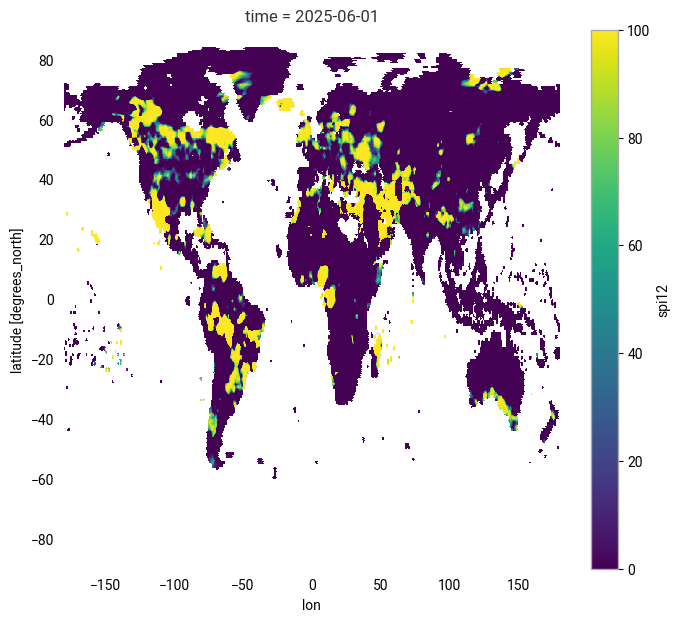

In [8]:
(100/51 * drought).isel(time=0)[f"{indicator.lower()}{str(window).zfill(2)}"].plot()
idata['lon']
print(idata.coords['lon'].max())
print(drought[f"{indicator.lower()}{str(window).zfill(2)}"].max())
print(100/51*drought[f"{indicator.lower()}{str(window).zfill(2)}"].min())

### Mask drought forecast

[-180.         -179.72222222 -179.44444444 ...  179.16666667  179.44444444
  179.72222222]
(640, 1296)
(640, 1296)


/etc/ecmwf/nfs/dh2_home_a/nejk/code/drought-on-demand/helpers/geodata.py:76: UserWarning: The indices of the left and right GeoSeries' are not equal, and therefore they will be aligned (reordering and/or introducing missing values) before executing the operation. If this alignment is the desired behaviour, you can silence this warning by passing 'align=True'. If you don't want alignment and protect yourself of accidentally aligning, you can pass 'align=False'.
  gpinside= gridpoint_df.within(polygon).astype(int).values


False
(7, 640, 1296)
<xarray.Dataset> Size: 16B
Dimensions:  ()
Coordinates:
    time     datetime64[ns] 8B 2025-06-01
Data variables:
    spi12    float64 8B nan
<xarray.Dataset> Size: 16B
Dimensions:  ()
Coordinates:
    time     datetime64[ns] 8B 2025-06-01
Data variables:
    spi12    float64 8B nan


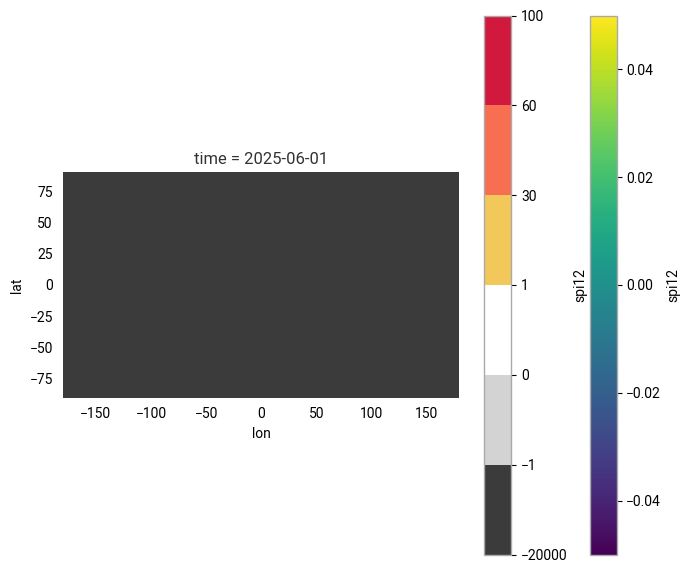

In [12]:
# get grid
lats = np.asarray(idata["lat"][:])
lons = np.asarray(idata["lon"][:])
print(lons)
grid_lon, grid_lat = np.meshgrid(lons, lats)
print(grid_lon.shape)
print(grid_lat.shape)
# create mask using polygon
gpoints = grid2df(grid_lon, grid_lat, ret='gpd', crs='epsg:4326')
shpfile.plot()
mask    = mask_gridpoints_in_polygon(gpoints, shpfile, return_shape=grid_lon.shape, crs='epsg:4326')
mask_3d = np.repeat(mask[np.newaxis, :, :], len(mdrought.time), axis=0)
print((mask==1).any())
print(mask_3d.shape)

# mask country datas
drought_country  = xr.where(mask_3d == 0, np.nan, drought)
mdrought_country = xr.where(mask_3d == 0, np.nan, mdrought)
sdrought_country = xr.where(mask_3d == 0, np.nan, sdrought)
edrought_country = xr.where(mask_3d == 0, np.nan, edrought)
# additionally set NaNs in country to -1 (-100/51)
#drought_country = xr.where(mask_3d == 1 & np.isnan(drought_country), -51/100, drought_country)
#mdrought_country = xr.where(mask_3d == 1 & np.isnan(mdrought_country), -51/100, mdrought_country)
#sdrought_country = xr.where(mask_3d == 1 & np.isnan(sdrought_country), -51/100, sdrought_country)
#edrought_country = xr.where(mask_3d == 1 & np.isnan(edrought_country), -51/100, edrought_country)

print(mdrought_country.isel(time=0).min())
print(mdrought_country.isel(time=0).max())
mdrought_country.isel(time=0)[f"{indicator.lower()}{str(window).zfill(2)}"].plot()
#if debug:
# color NaNs grey
prob_levels=[-20000,-1.1, 0, 1, 30, 60, 100.1]
prob_collist=["#3b3b3b","#D3D3D3","#ffffff", "#f2c85b", "#f86e51", "#d1193e", "#3a0751"]
idata = xr.where(mask == 0, np.nan, mdrought_country)
idata = xr.where(np.isnan(idata), -9999, idata)
#(100/51 * mdrought_country).isel(time=0)[f"{indicator.lower()}{str(window).zfill(2)}"].plot(
(100/51 * idata).isel(time=0)[f"{indicator.lower()}{str(window).zfill(2)}"].plot(
    levels=prob_levels, 
    colors=prob_collist, 
    vmin=-10000, vmax=100
)
#plt.xlim(xlims)
#plt.ylim(ylims)